In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

from results_loader import load_results, summary_table

CONFIGS = {"GATAS_scale_0.5": "scale 0.5", "GATAS_scale_1": "scale 1", "GATAS_scale_2": "scale 2", "GATAS_adaptive": "adaptive"}
records = load_results("../outputs/results", dataset="harvard", asr_model="whisper-tiny", methods=list(CONFIGS))
configs = [c for c in CONFIGS if records[c]]  # skip configurations without results yet

## Main table

In [2]:
table = summary_table({CONFIGS[c]: records[c] for c in configs}).round(3)
display(table)

,test case found %,lexical (WER),semantic,spectrogram,UTMOS
scale 0.5,35.0,0.092,0.076,0.025,4.398
scale 1,55.0,0.124,0.148,0.047,4.379
scale 2,100.0,0.274,0.324,0.068,4.238
adaptive,100.0,0.387,0.321,0.081,3.964


## Trade-off: found vs. naturalness

One marker per configuration (mean over sentences); the line connects the Pareto front, crosses are dominated configurations.

utmos front: ['scale 2', 'scale 1', 'scale 0.5']
spec front: ['scale 2', 'scale 1', 'scale 0.5']


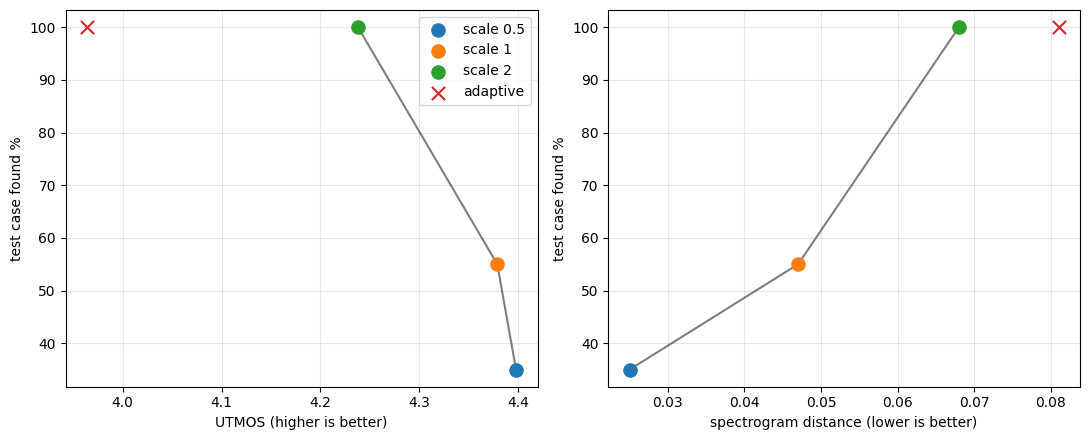

In [3]:
from results_loader import pareto_plot

points = table.rename(columns={"test case found %": "found", "UTMOS": "utmos", "spectrogram": "spec"}).to_dict("index")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, key, label, higher in zip(axes, ("utmos", "spec"), ("UTMOS (higher is better)", "spectrogram distance (lower is better)"), (True, False)):
    front = pareto_plot(ax, points, key, "found", x_higher_better=higher)
    ax.set_xlabel(label)
    ax.set_ylabel("test case found %")
    print(key, "front:", front)
axes[0].legend()
plt.tight_layout()
plt.savefig("_figures/ablation_scale_tradeoff.pdf", bbox_inches="tight")

## Scale chosen by the adaptive search

Scale of the selected final candidate per sentence.

mean 1.70, median 1.19, min 0.52, max 3.78


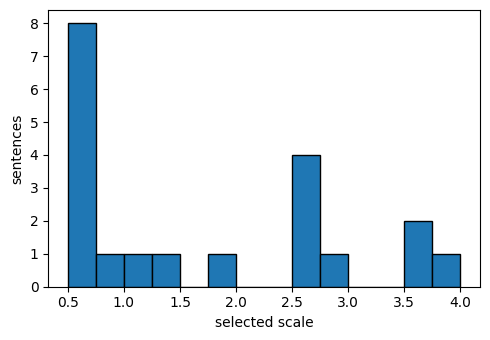

In [4]:
if records.get("GATAS_adaptive"):
    scales = [r["scale"] for r in records["GATAS_adaptive"] if r.get("scale") is not None]
    print(f"mean {np.mean(scales):.2f}, median {np.median(scales):.2f}, min {np.min(scales):.2f}, max {np.max(scales):.2f}")
    plt.figure(figsize=(5, 3.5))
    plt.hist(scales, bins=np.arange(0.5, 4.01, 0.25), edgecolor="black")
    plt.xlabel("selected scale")
    plt.ylabel("sentences")
    plt.tight_layout()
    plt.savefig("_figures/ablation_scale_chosen.pdf", bbox_inches="tight")